# Analysis of the tune grid results

Tables and figures for the tune grid, produced by the functions in `grant_eval.analysis`.

In [1]:
import os
from pathlib import Path

from IPython.display import Image, display

from grant_eval.analysis import contrasts as con
from grant_eval.analysis import dataset as ds
from grant_eval.analysis import edgecases as ec
from grant_eval.analysis import errors as err
from grant_eval.analysis import fields as fld
from grant_eval.analysis import frontier as fr
from grant_eval.analysis import funders as fm
from grant_eval.analysis import report
from grant_eval.analysis import sensitivity as sens
from grant_eval.analysis import telemetry as tel
from grant_eval.scoring.groundtruth import load_ground_truth

# nbconvert runs from the notebook folder, but the paths are relative to the repo root.
if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)

FIGURES = Path("eval/figures")


Error: No connection selected.

## Provenance

In [ ]:
data = ds.load_dataset()
gt = load_ground_truth()
manifest = data.manifest

print(f"scorer source hash: {manifest['scorer']['source_hash']}")
print(f"scorer git sha: {manifest['scorer']['git']['sha']} "
      f"(dirty={manifest['scorer']['git']['dirty']})")
print()
print(f"ground truth: {manifest['ground_truth']['n_funders']} funders, "
      f"{manifest['ground_truth']['n_rows']} rows, "
      f"{manifest['ground_truth']['n_in_scope']} in scope")
print(f"scored runs: {manifest['counts']['n_scored']} "
      f"({manifest['counts']['n_configs']} configs, "
      f"{manifest['counts']['n_skipped']} skipped)")
print()
print("mirror snapshot dates:")
for name, snap in sorted(manifest["mirror"]["snapshots"].items()):
    print(f"  {snap['snapshot_date']}  {name}")


scorer source hash: 67c1b6e752f63eef61c6c7e0dde9d20838d230d8ecf146f65880b0962cc1b809
scorer git sha: 5d730ca46b6281cea2287d947da33182fc1cd69b (dirty=True)

ground truth: 25 funders, 311 rows, 167 in scope
scored runs: 1920 (24 configs, 0 skipped)

mirror snapshot dates:
  2026-08-16  British Ecological Society
  2026-08-21  Cara (Council for At-Risk Academics)
  2026-08-16  Carnegie Trust for the Universities of Scotland
  2026-08-16  Garfield Weston Foundation
  2026-08-21  Great Britain Sasakawa Foundation
  2026-08-21  Hakluyt Society
  2026-08-14  Henry Moore Foundation
  2026-08-16  National Lottery Heritage Fund
  2026-08-21  Nuffield Farming Scholarships Trust
  2026-08-16  Nuffield Foundation
  2026-08-28  PRS Foundation
  2026-08-16  Paul Mellon Centre for Studies in British Art
  2026-08-16  Royal Historical Society
  2026-08-21  Royal Society of Chemistry
  2026-08-21  Society of Antiquaries of London
  2026-08-21  Society of Authors
  2026-08-28  The British Academy
  2026-

## Scope and caveats

In [ ]:
print(report.scope_notes(data))


SCOPE
This report covers the 16 tune funders and their 98 in-scope ground-truth rows only.
RQ6 (the tune-to-validation gap) and the comparison against Pivot-RP are OUT OF SCOPE here: the validation run has not happened yet, and no Pivot-RP data exists to compare against. A silent gap is worse than a stated one, so this is stated rather than left implicit.
Funder type (D-F) and structural complexity (D-E) were both defined after seeing the tune data and are exploratory, not confirmatory: neither is ever statistically tested. Structural complexity is additionally partly a measurement artefact: the match key (identity.match_key) consults a candidate's title only when its normalised URL is shared by more than one of a funder's ground-truth rows, so a 'packed' funder is exactly where an agent's paraphrase of a title is most likely to be scored ambiguous_title, the grid's largest false-positive class — not necessarily where the page is genuinely harder to parse.
js_portal has no tune rows an

## Leaderboard

In [ ]:
print(report.leaderboard(data))


LEADERBOARD — macro F1 across all 24 configurations, best first
    #  config                                                                  macroF1   macroP   macroR  funders
    1  openrouter/deepseek/deepseek-v4-flash-0731 | few_shot | t0.7              0.793    0.847    0.777       16
    2  openrouter/deepseek/deepseek-v4-flash-0731 | minimal | t0.7               0.786    0.835    0.782       16
    3  openrouter/deepseek/deepseek-v4-flash-0731 | structured | t0.7            0.784    0.853    0.764       16
    4  openrouter/deepseek/deepseek-v4-flash-0731 | chain_of_thought | t0.7      0.768    0.822    0.762       16
    5  openrouter/deepseek/deepseek-v4-flash-0731 | chain_of_thought | t0.0      0.752    0.847    0.748       16
    6  openrouter/deepseek/deepseek-v4-flash-0731 | structured | t0.0            0.749    0.866    0.728       16
    7  openrouter/deepseek/deepseek-v4-flash-0731 | few_shot | t0.0              0.722    0.838    0.709       16
    8  openrouter/deepse

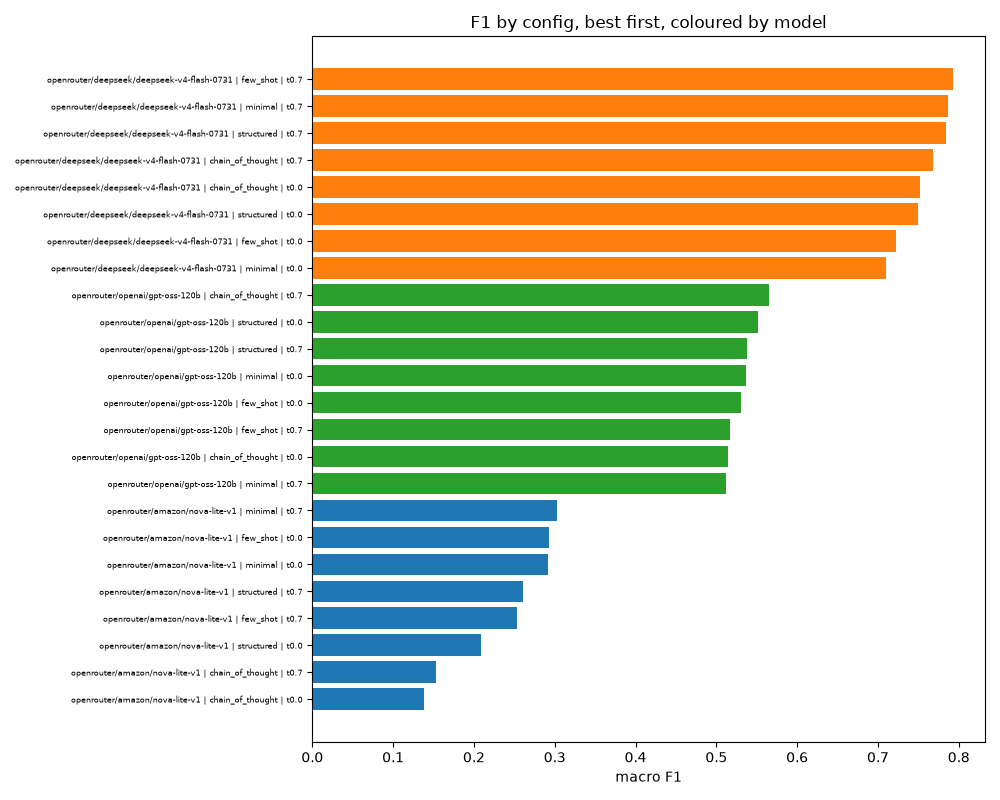

In [ ]:
display(Image(filename=str(FIGURES / "f1_by_config.png")))


## What actually gets delivered

In [ ]:
field_acc = fld.field_accuracy(data, gt)
print(report.field_accuracy_table(field_acc))

STRUCTURED FIELD ACCURACY — exact match, pooled over opportunities; CONDITIONAL ON DETECTION (see 'n eval.')
  group                            deadlines   n eval.    amount_max_gbp   n eval.    amount_min_gbp   n eval.            status   n eval.
  nova-lite-v1                         0.523       530             0.397       572             0.467       589             0.606       620
  deepseek-v4-flash-0731               0.716      2162             0.827      2477             0.874      2595             0.911      2674
  gpt-oss-120b                         0.669      1361             0.502      1684             0.736      1717             0.891      1757

A field is only scorable on an opportunity the run actually found, so these accuracies sit over different populations and are NOT a like-for-like ranking: the weakest model's figures rest on the easiest opportunities it reached. END-TO-END below puts detection and extraction on one denominator, where that selection effect cannot hid

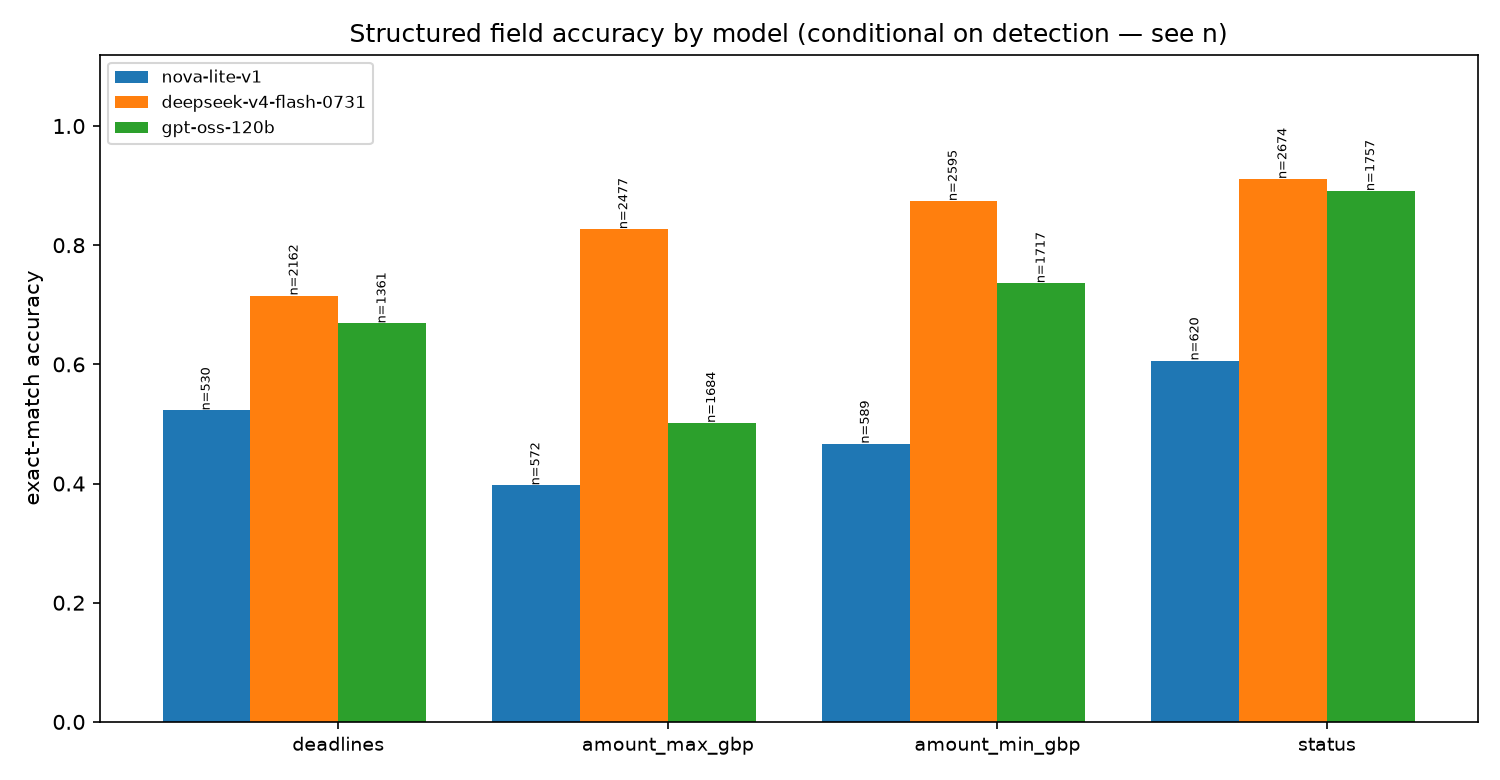

In [ ]:
display(Image(filename=str(FIGURES / "field_accuracy.png")))

### Delivered results per config and per prompt strategy

In [ ]:
print(report.field_by_config_table(fld.field_accuracy(data, gt, key="config")))

STRUCTURED FIELD ACCURACY BY CONFIG — exact match; ordered by deadline accuracy; CONDITIONAL ON DETECTION
  config                                                                        deadlines   amount_max_gbp   amount_min_gbp           status
  openrouter/openai/gpt-oss-120b | minimal | t0.7                                   0.742            0.550            0.756            0.886
  openrouter/deepseek/deepseek-v4-flash-0731 | chain_of_thought | t0.7              0.739            0.858            0.914            0.879
  openrouter/deepseek/deepseek-v4-flash-0731 | few_shot | t0.0                      0.734            0.754            0.830            0.978
  openrouter/deepseek/deepseek-v4-flash-0731 | few_shot | t0.7                      0.731            0.791            0.871            0.948
  openrouter/openai/gpt-oss-120b | minimal | t0.0                                   0.731            0.568            0.738            0.908
  openrouter/deepseek/deepseek-v4-flash-0731 | c

In [ ]:
print(report.field_factor_table(fld.field_accuracy_by_factor(data, gt, "prompt")))
print()
print(report.field_factor_table(fld.field_accuracy_by_factor(data, gt, "temperature")))

STRUCTURED FIELD ACCURACY BY PROMPT, WITHIN MODEL — EXPLORATORY: no field-level contrast is pre-registered
  nova-lite-v1
    prompt                    deadlines       n   amount_max_gbp       n   amount_min_gbp       n           status       n
    chain_of_thought              0.627      83            0.372      78            0.468      79            0.598      92
    few_shot                      0.518     164            0.000     172            0.758     178            0.659     182
    minimal                       0.485     163            0.572     180            0.335     188            0.608     199
    structured                    0.508     120            0.669     142            0.278     144            0.544     147

  deepseek-v4-flash-0731
    prompt                    deadlines       n   amount_max_gbp       n   amount_min_gbp       n           status       n
    chain_of_thought              0.734     548            0.841     637            0.889     666            0.900

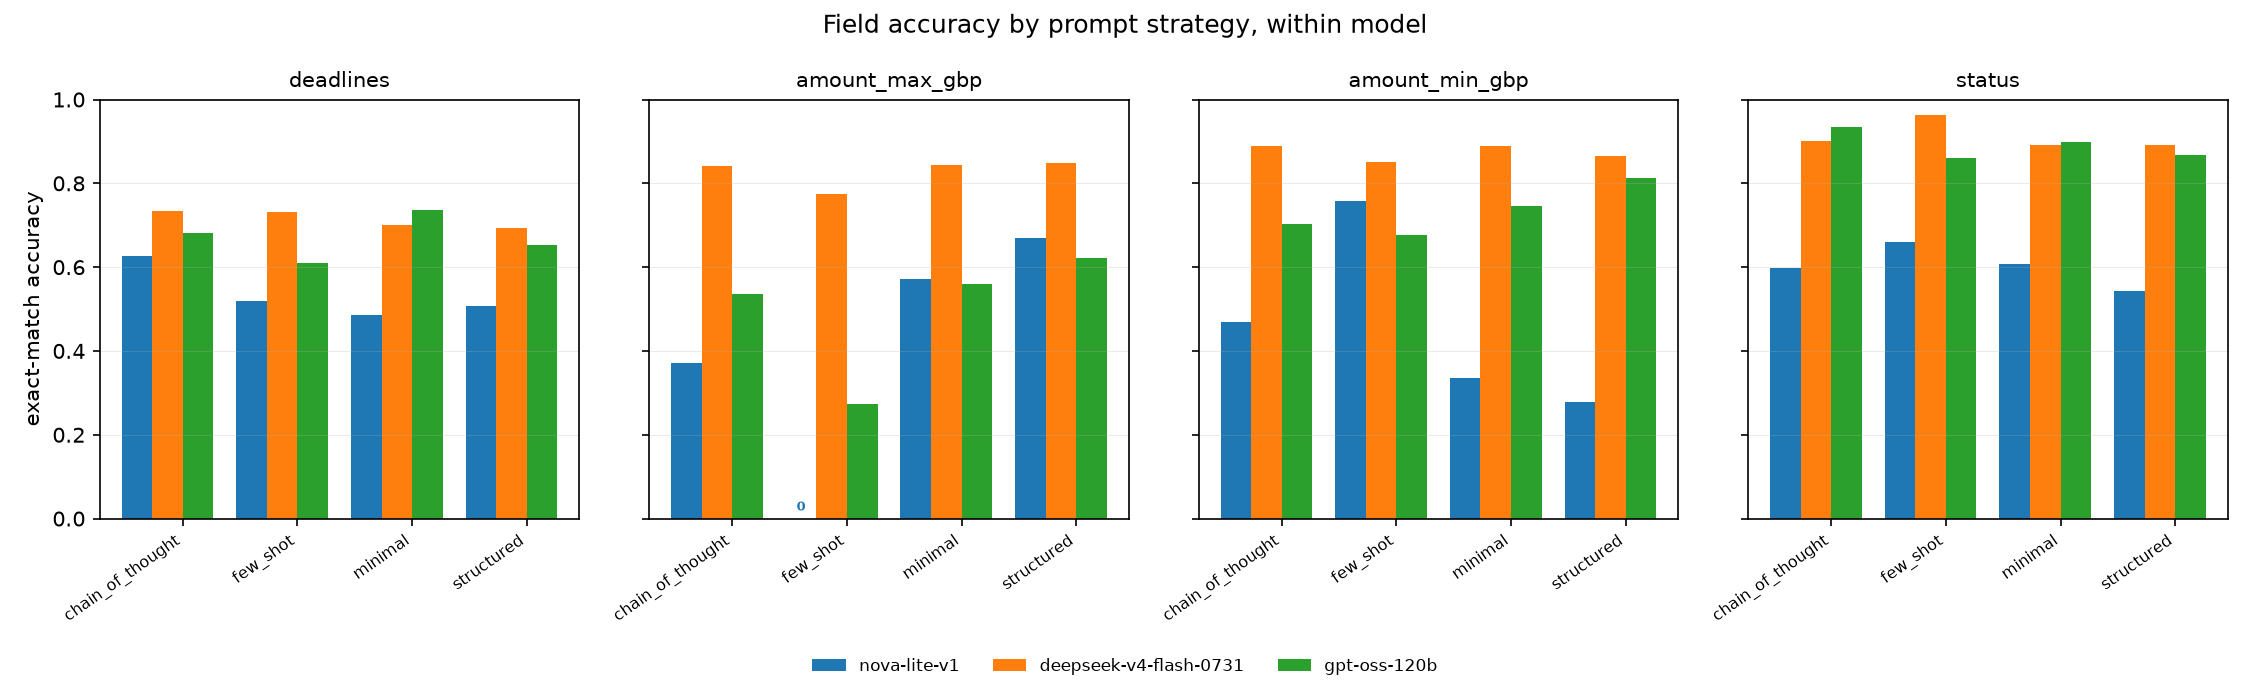

In [ ]:
display(Image(filename=str(FIGURES / "field_by_prompt.png")))

## Which way the errors run

In [ ]:
print(report.field_direction_table(fld.field_directions(data)))

FIELD ERROR DIRECTION — 'asserted' = agent supplied a value the truth does not have; 'omitted' = agent left blank a value the truth has
  group                          deadlines asrt/omit  amount_max_gbp asrt/omit  amount_min_gbp asrt/omit          status asrt/omit
  nova-lite-v1                               22 / 95                   0 / 304                  214 / 68                     0 / 0
  deepseek-v4-flash-0731                    337 / 39                   0 / 400                  67 / 143                     0 / 0
  gpt-oss-120b                              225 / 37                   0 / 767                  54 / 290                     0 / 0

The two are different product failures and one accuracy figure pools them: an asserted value is an invention a user may act on, an omission is a gap they can see. A field whose errors are overwhelmingly omissions is failing conservatively; one whose errors are assertions is not.


## End-to-end result

In [ ]:
e2e_deadlines = fld.end_to_end_frontier(fld.end_to_end(data, gt, field="deadlines"))
print(report.end_to_end_table(e2e_deadlines))

END-TO-END RESULT (field = deadlines) — share of ALL in-scope opportunities both found AND correctly extracted; 75 opportunities, 23 excluded as uncertain
  config                                                                  detected  end-to-end     gap   cost $   $/usable  frontier
  openrouter/deepseek/deepseek-v4-flash-0731 | few_shot | t0.7               0.693       0.540  -0.153    1.016     0.0251       yes
  openrouter/deepseek/deepseek-v4-flash-0731 | chain_of_thought | t0.7       0.683       0.534  -0.149    1.006     0.0251       yes
  openrouter/deepseek/deepseek-v4-flash-0731 | minimal | t0.7                0.692       0.524  -0.168    0.807     0.0206       yes
  openrouter/deepseek/deepseek-v4-flash-0731 | chain_of_thought | t0.0       0.638       0.500  -0.138    1.693     0.0451        no
  openrouter/deepseek/deepseek-v4-flash-0731 | structured | t0.7             0.663       0.484  -0.179    0.956     0.0263        no
  openrouter/deepseek/deepseek-v4-flash-0731 | 

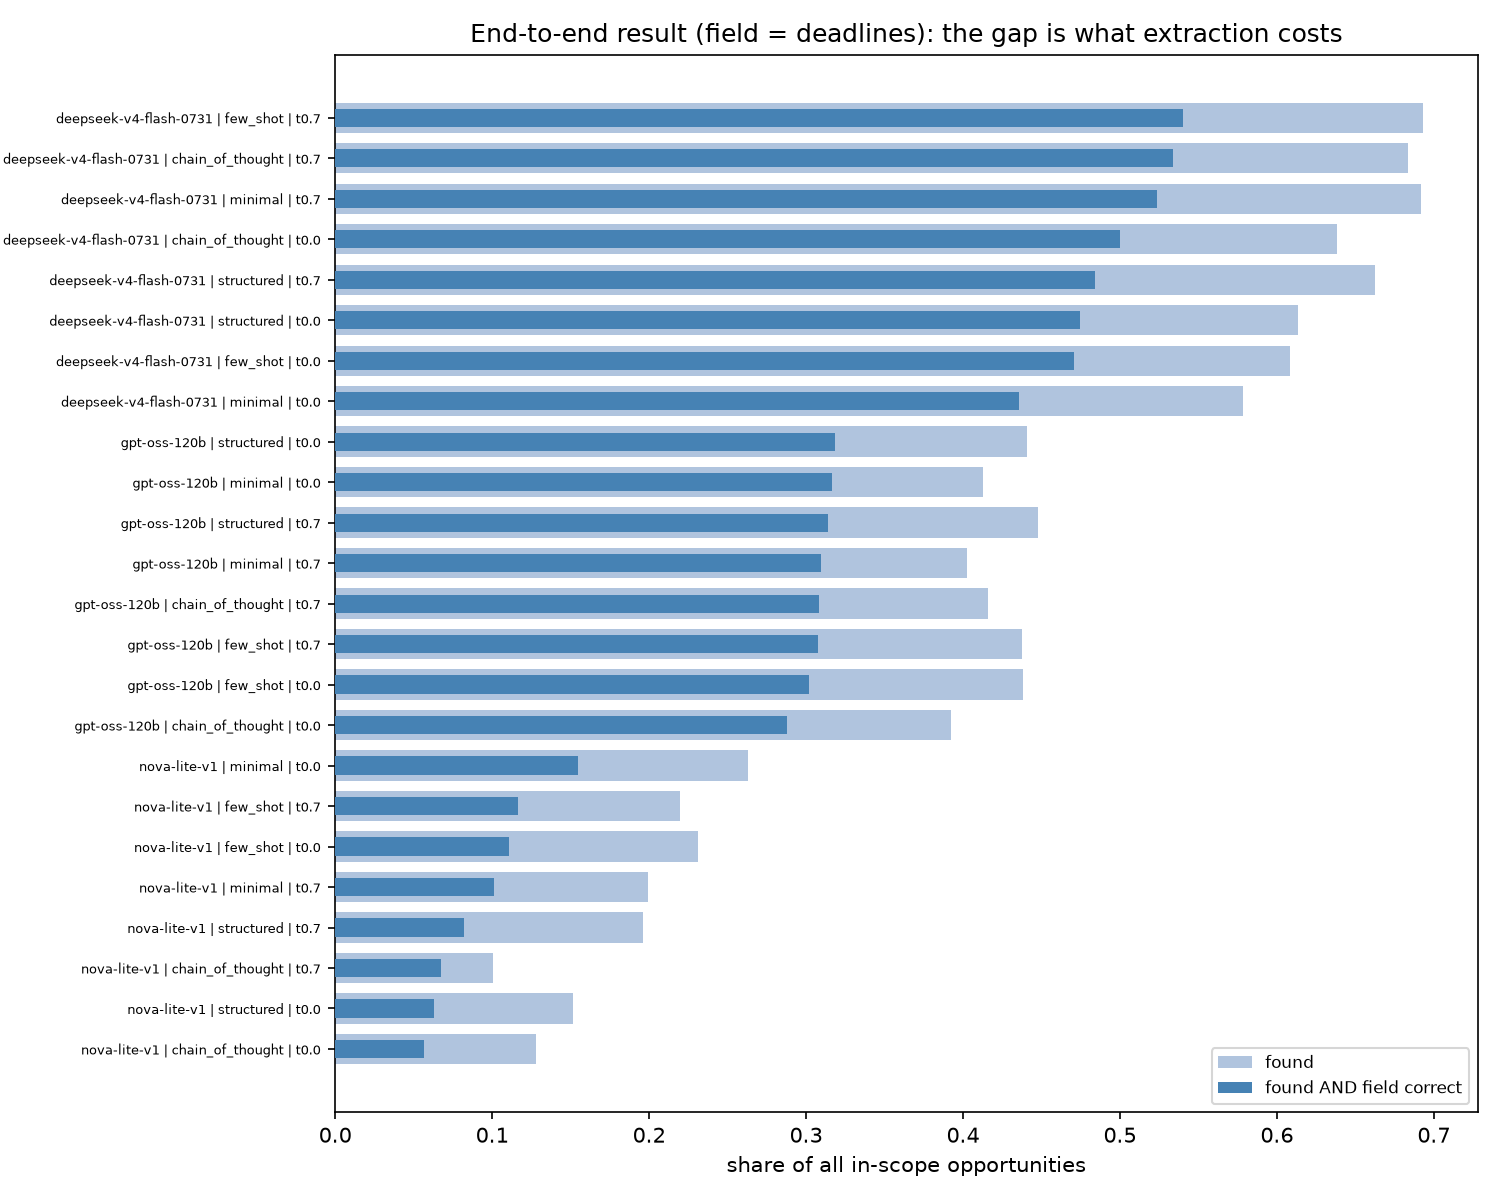

In [ ]:
display(Image(filename=str(FIGURES / "end_to_end.png")))

## Best combination, and best for the money

In [ ]:
e2e_all = fld.end_to_end_frontier(fld.end_to_end(data, gt, field="all"))
print(report.end_to_end_table(e2e_all))

END-TO-END RESULT (field = all) — share of ALL in-scope opportunities both found AND correctly extracted; 53 opportunities, 45 excluded as uncertain
  config                                                                  detected  end-to-end     gap   cost $   $/usable  frontier
  openrouter/deepseek/deepseek-v4-flash-0731 | chain_of_thought | t0.7       0.735       0.379  -0.356    1.006     0.0501       yes
  openrouter/deepseek/deepseek-v4-flash-0731 | minimal | t0.7                0.717       0.376  -0.341    0.807     0.0405       yes
  openrouter/deepseek/deepseek-v4-flash-0731 | few_shot | t0.7               0.726       0.373  -0.352    1.016     0.0514        no
  openrouter/deepseek/deepseek-v4-flash-0731 | structured | t0.7             0.690       0.339  -0.351    0.956     0.0532        no
  openrouter/deepseek/deepseek-v4-flash-0731 | few_shot | t0.0               0.671       0.332  -0.339    1.816     0.1031        no
  openrouter/deepseek/deepseek-v4-flash-0731 | struct

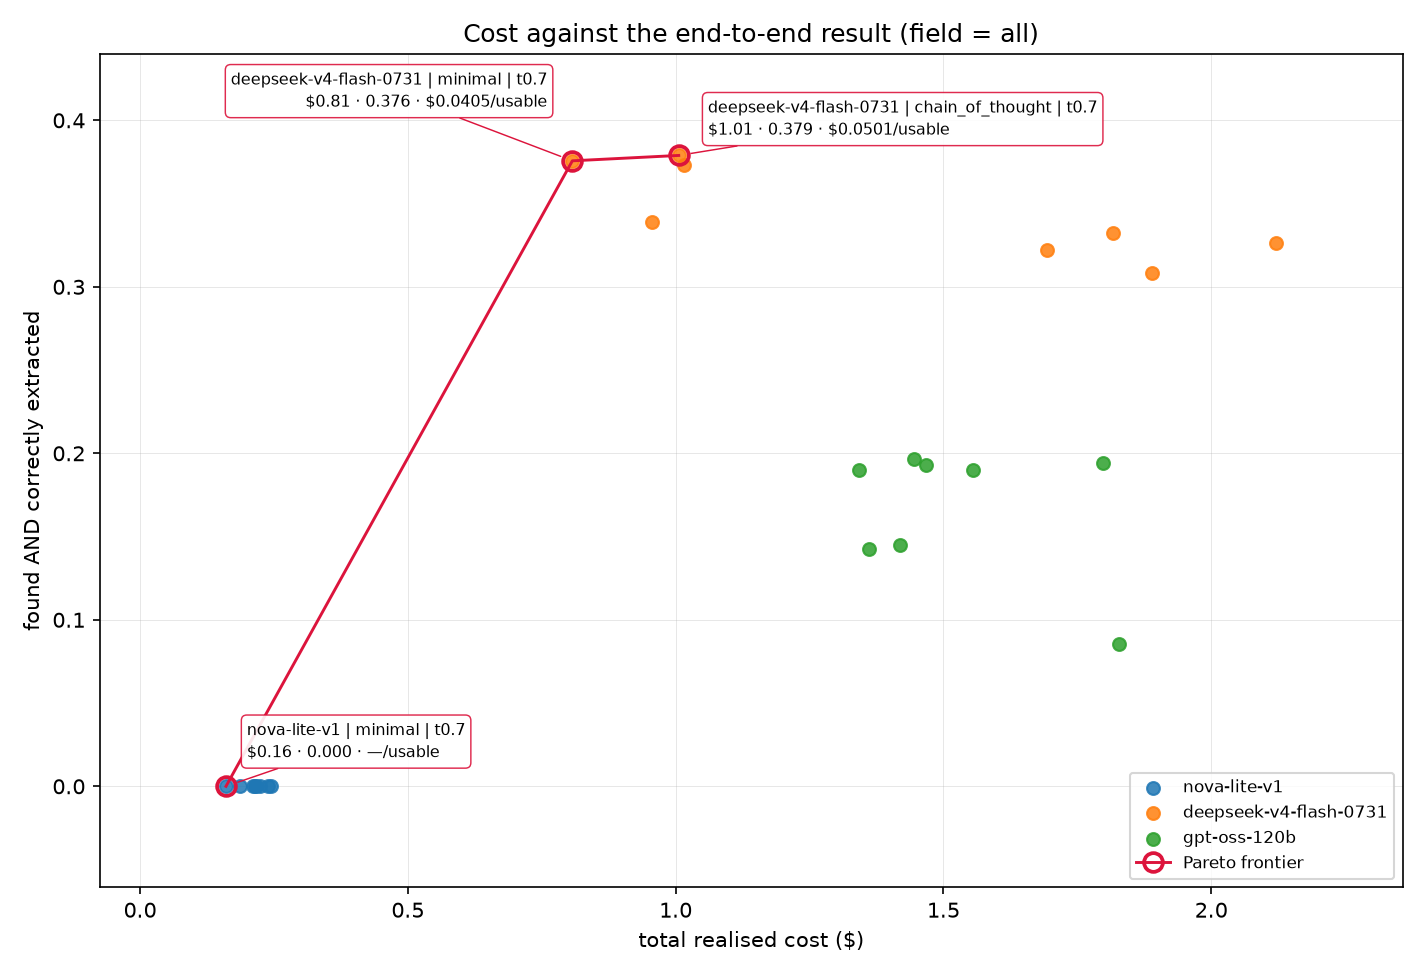

In [ ]:
display(Image(filename=str(FIGURES / "end_to_end_frontier.png")))

## Per-funder detail for the best config

In [ ]:
best_label = ds.config_label(
    "openrouter/deepseek/deepseek-v4-flash-0731", "few_shot", 0.7
)
print(report.per_funder_table(data, best_label))


PER-FUNDER — openrouter/deepseek/deepseek-v4-flash-0731 | few_shot | t0.7
  funder                                              n reps   prec    rec     F1  stable   kappa
  British Ecological Society                          8    5  1.000  0.975  0.987   1.000  -0.026
  Cara (Council for At-Risk Academics)                1    5  1.000  1.000  1.000   1.000       —
  Carnegie Trust for the Universities of Scotland     1    5  0.800  1.000  0.867   1.000       —
  Garfield Weston Foundation                          2    5  0.500  0.500  0.500   1.000   1.000
  Great Britain Sasakawa Foundation                   2    5  1.000  1.000  1.000   1.000       —
  Henry Moore Foundation                              6    5  0.333  0.167  0.222   1.000   1.000
  Nuffield Farming Scholarships Trust                 2    5  1.000  0.500  0.667   1.000   1.000
  Nuffield Foundation                                 2    5  0.867  1.000  0.920   1.000       —
  Paul Mellon Centre for Studies in British 

## Confirmatory contrasts

In [ ]:
family = con.confirmatory_family(data)
print(report.contrast_table(family))


CONFIRMATORY CONTRASTS (D-A) — pre-registered within-factor family, Holm-corrected together
  factor       level_a                 level_b                    mean d  median d  rank-biserial        p   Holm p    95% CI (n=16 clusters)  reject
  model        nova-lite-v1            deepseek-v4-flash-0731     -0.520    -0.497         -1.000    0.000    0.000          [-0.622, -0.421]     yes
  model        nova-lite-v1            gpt-oss-120b               -0.295    -0.340         -0.900    0.001    0.008          [-0.411, -0.169]     yes
  model        deepseek-v4-flash-0731  gpt-oss-120b                0.225     0.148          0.779    0.004    0.033            [0.090, 0.375]     yes
  prompt       chain_of_thought        few_shot                   -0.036    -0.040         -0.574    0.044    0.310           [-0.075, 0.005]      no
  prompt       chain_of_thought        minimal                    -0.041    -0.026         -0.467    0.121    0.603          [-0.085, -0.002]      no
  prompt

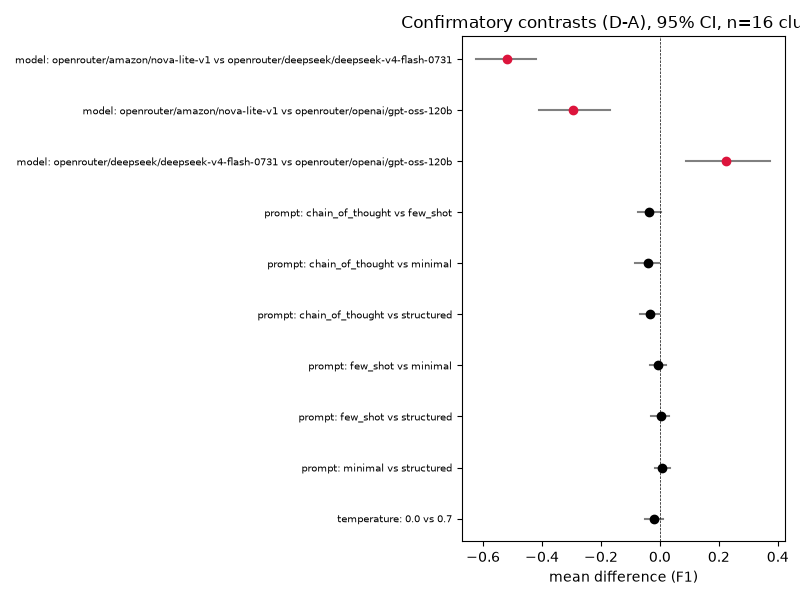

In [ ]:
display(Image(filename=str(FIGURES / "contrasts.png")))


## Factor effects and the pre-registered interaction

In [ ]:
print(report.interaction_note(data))


PRE-REGISTERED INTERACTION (D-B)
Predicted: largest on nova-lite. Observed: largest on openrouter/amazon/nova-lite-v1, negative.
(chain_of_thought - minimal) on nova-lite-v1 minus the same gap on deepseek-v4-flash-0731 = -0.164 (negative), 95% CI [-0.285, -0.052] (n=16 clusters).
The interaction is negative: the scaffold pre-registration predicted would help most on nova-lite — it has no reasoning mode of its own — instead hurts most there, the opposite of the predicted direction.


In [ ]:
print(report.temperature_note(data, family))


TEMPERATURE: MAIN EFFECT AND INTERACTION WITH MODEL
No temperature main effect (Holm p 1.000; see CONFIRMATORY CONTRASTS above).
Temperature x model interaction (t0.7 - t0.0 difference-in-differences), funder-clustered bootstrap CI:
  nova-lite-v1 vs deepseek-v4-flash-0731: -0.0402 [-0.109, +0.026] (n=16 clusters) — crosses zero
  nova-lite-v1 vs gpt-oss-120b: +0.0096 [-0.046, +0.076] (n=16 clusters) — crosses zero
  deepseek-v4-flash-0731 vs gpt-oss-120b: +0.0498 [-0.029, +0.140] (n=16 clusters) — crosses zero
Every computed interval crosses zero: there is no evidence of a temperature x model interaction in F1. Combined with the main effect above, there is no detectable effect of temperature on F1, overall or for any model. Two caveats on that: these three interaction contrasts are POST HOC (examined only after the main-effect result was seen) and UNCORRECTED for multiplicity, unlike the ten-contrast confirmatory family above, so 'no detectable effect' is as far as this goes — it is n

## Reliability (RQ3)

In [ ]:
print(report.reliability_table(data))


RELIABILITY (RQ3) — mean stable-rate and mean Fleiss' kappa across funders, per config
  config                                                                  stable-rate    kappa
  openrouter/amazon/nova-lite-v1 | chain_of_thought | t0.0                      0.117    0.243
  openrouter/amazon/nova-lite-v1 | chain_of_thought | t0.7                      0.148    0.063
  openrouter/amazon/nova-lite-v1 | few_shot | t0.0                              0.301   -0.045
  openrouter/amazon/nova-lite-v1 | few_shot | t0.7                              0.189   -0.024
  openrouter/amazon/nova-lite-v1 | minimal | t0.0                               0.536    0.131
  openrouter/amazon/nova-lite-v1 | minimal | t0.7                               0.232   -0.049
  openrouter/amazon/nova-lite-v1 | structured | t0.0                            0.106    0.027
  openrouter/amazon/nova-lite-v1 | structured | t0.7                            0.146    0.034
  openrouter/deepseek/deepseek-v4-flash-0731 | chain_of_th

## Strata

In [ ]:
print(report.stratum_table(data, gt))


STRATA (D-C) — edge-case tags, tune-only row/cluster counts
  tag                       rows  clusters        status  reason
  rolling                     10         6   descriptive  10 rows (< 20) and 6 funder-clusters (< 8)
  multi_deadline              32        10   inferential  clears both D-C thresholds
  pdf_only                     1         1   descriptive  1 rows (< 20) and 1 funder-clusters (< 8)
  js_portal                    0         0        absent  no tune rows carry this tag
  ambiguous_eligibility        5         4   descriptive  5 rows (< 20) and 4 funder-clusters (< 8)
  restricted                  50        11   inferential  clears both D-C thresholds


## Do edge cases cost recall?

In [ ]:
edge_contrasts = ec.tag_contrast_family(data, gt)
print(report.edge_case_table(edge_contrasts))

EDGE-CASE CONTRAST (D-C, extended) — mean recall on tagged rows MINUS mean recall on UNTAGGED rows, paired within funder; negative means the tag costs recall
  tag                           rows  tag clu.  paired clu.   tagged  untagged     diff              95% CI        status
  restricted                      50        11            4    0.465     0.435    0.030    [-0.096, +0.140]   descriptive
  multi_deadline                  32        10            6    0.429     0.481   -0.052    [-0.315, +0.134]   descriptive
  rolling                         10         6            3    0.564     0.552    0.012    [-0.126, +0.119]   descriptive
  ambiguous_eligibility            5         4            3    0.408     0.390    0.018    [-0.071, +0.078]   descriptive
  pdf_only                         1         1            1    0.617     0.586    0.031                   —   descriptive

  restricted: 4 paired funder-cluster(s) (< 8)
  multi_deadline: 6 paired funder-cluster(s) (< 8)
  rolling: 

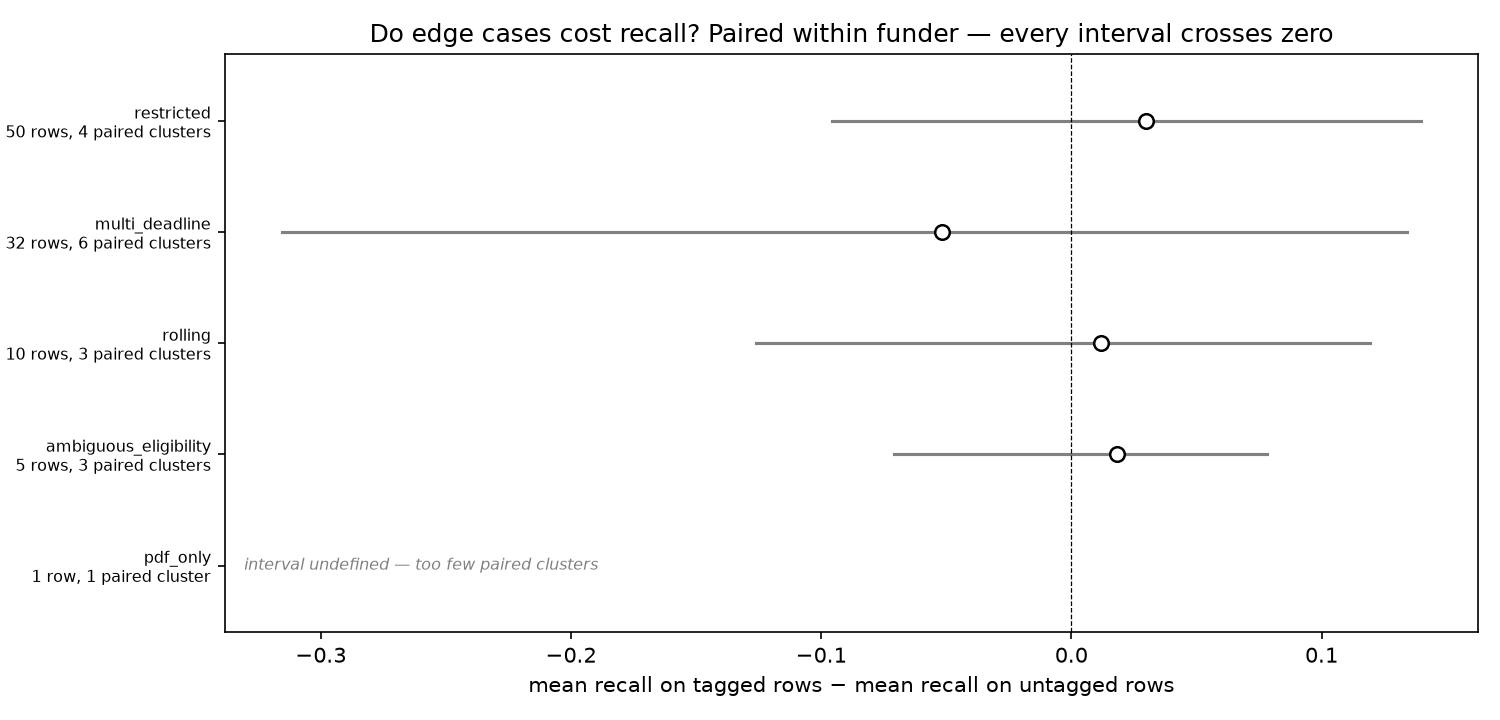

In [ ]:
display(Image(filename=str(FIGURES / "edge_cases.png")))

## Why the tags cannot be read independently

In [ ]:
print(report.tag_overlap_table(ec.tag_cooccurrence(gt, data.funders())))

EDGE-CASE TAG OVERLAP — in-scope tune rows carrying BOTH tags; the diagonal is the tag's own row count
  tag                      ambiguous_el  multi_deadli      pdf_only    restricted       rolling
  ambiguous_eligibility               5             1             0             1             0
  multi_deadline                      1            32             0            19             1
  pdf_only                            0             0             1             1             0
  restricted                          1            19             1            50             4
  rolling                             0             1             0             4            10

Where two tags share most of their rows, their marginal contrasts are substantially the same rows measured twice and cannot be read as independent effects.


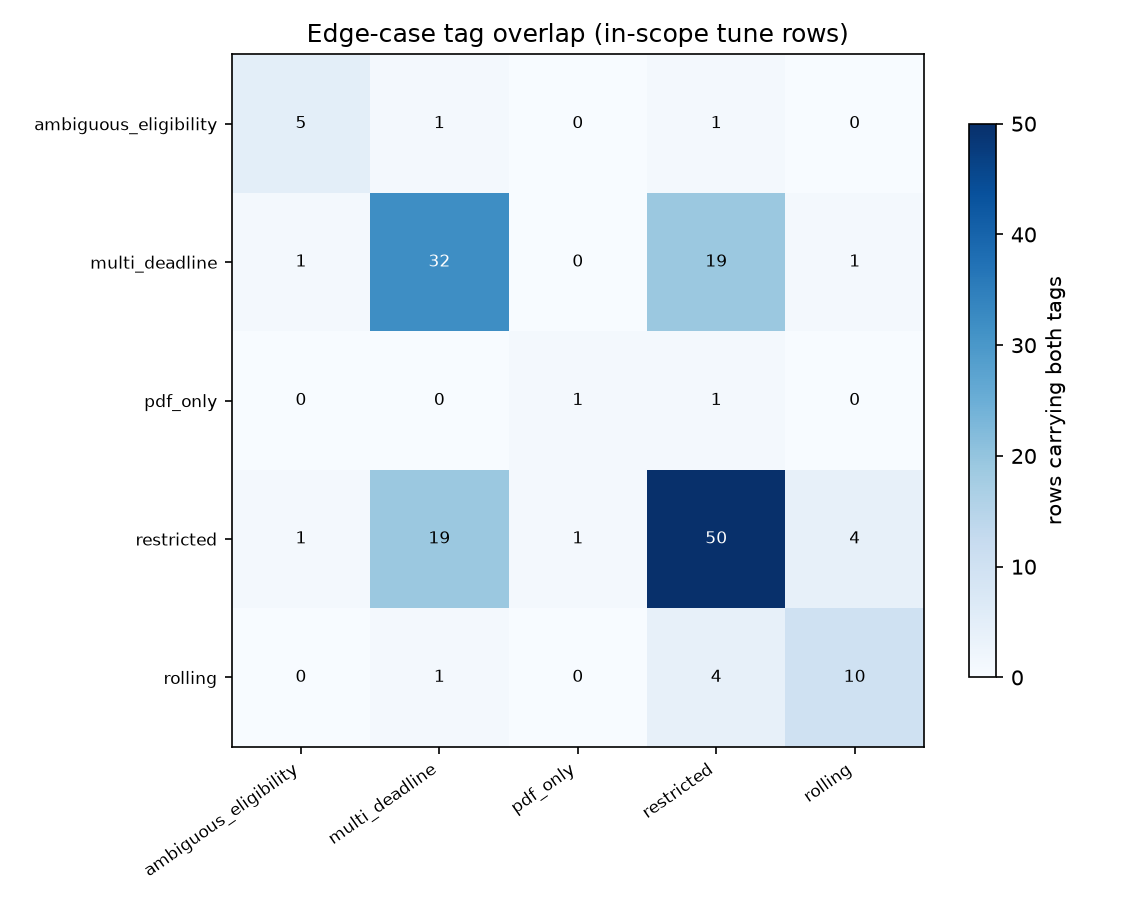

In [ ]:
display(Image(filename=str(FIGURES / "edge_case_overlap.png")))

## Does stacking edge cases compound?

In [ ]:
print(report.tag_count_table(ec.recall_by_tag_count(data, gt)))

RECALL BY EDGE-CASE COUNT — does stacking edge cases compound? EXPLORATORY: the bands were defined after seeing the tag distribution
  tags on row        rows  clusters  mean recall                95% CI
  0                    27         7        0.485      [+0.267, +0.681]
  1                    44        12        0.516      [+0.382, +0.649]
  2                    27        10        0.407      [+0.244, +0.564]

Intervals here are on each band's own mean, not on a difference between bands, and they overlap: this table shows the shape, it does not test it.


## Edge cases hurt extraction, not detection

In [ ]:
field_tags = [
    fld.field_accuracy_by_tag(data, gt, f, t)
    for t in ("multi_deadline", "restricted", "rolling")
    for f in fld.FIELDS
]
print(report.field_by_tag_table(field_tags))

FIELD ACCURACY BY EDGE-CASE TAG — accuracy on tagged rows MINUS accuracy on UNTAGGED rows, paired within funder; negative means the tag costs accuracy
  tag             field              rows  paired clu.   tagged  untagged     diff              95% CI
  multi_deadline  deadlines            32            5    0.191     0.790   -0.599    [-0.806, -0.399]
  multi_deadline  amount_max_gbp       32            5    0.497     0.561   -0.064    [-0.181, +0.006]
  multi_deadline  amount_min_gbp       32            5    0.577     0.851   -0.274    [-0.711, +0.131]
  multi_deadline  status               32            4    0.914     0.742    0.172    [-0.002, +0.467]
  restricted      deadlines            50            4    0.462     0.678   -0.217    [-0.408, -0.007]
  restricted      amount_max_gbp       50            4    0.330     0.439   -0.110    [-0.220, -0.008]
  restricted      amount_min_gbp       50            4    0.745     0.823   -0.077    [-0.188, +0.033]
  restricted      status 

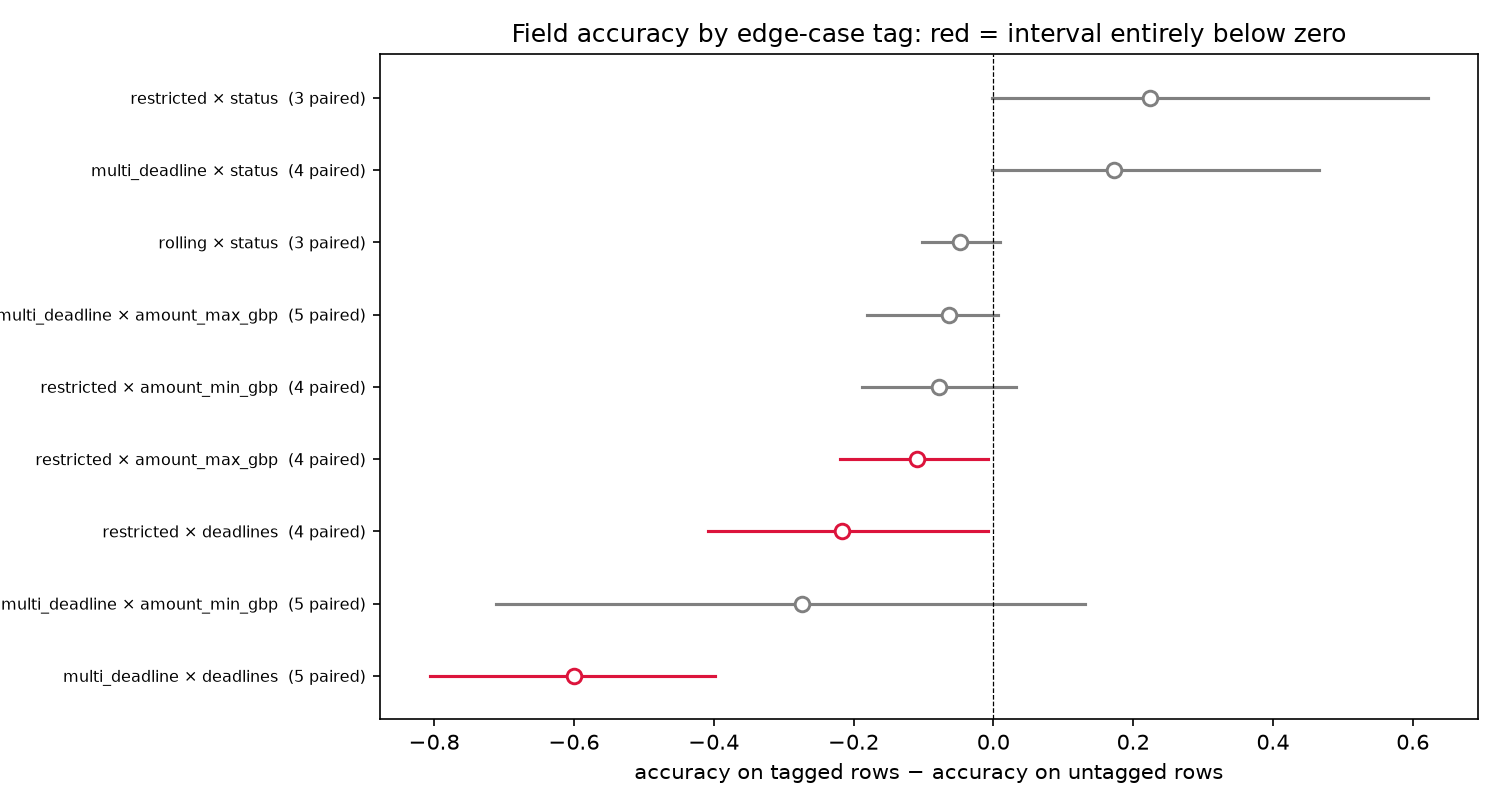

In [ ]:
display(Image(filename=str(FIGURES / "field_by_tag.png")))

## Funder type (exploratory)

In [ ]:
profiles = fm.load_profiles()
print(report.funder_type_table(data, profiles))


FUNDER TYPE (D-F) — EXPLORATORY, defined after seeing the tune data; never statistically tested
  type_group         n_funders   mean F1 (all runs)
  charity                    5                0.494
  membership_body            6                0.508
  niche_trust                5                0.527


## Structural complexity (exploratory)

In [ ]:
print(report.complexity_table(data, profiles))


STRUCTURAL COMPLEXITY (D-E) — rows_per_url; EXPLORATORY and partly a measurement artefact (see funders.py: the match key consults titles only on shared URLs, so a packed funder is exactly where paraphrase produces the largest false-positive class, ambiguous_title)
  funder                                            rows/url          band   mean F1 (all runs)
  Society of Antiquaries of London                      3.67        packed                0.157
  Henry Moore Foundation                                3.50        packed                0.133
  Wolfson Foundation                                    1.29  one_per_page                0.499
  Cara (Council for At-Risk Academics)                  1.14  one_per_page                0.400
  The British Academy                                   1.00  one_per_page                0.773
  British Ecological Society                            1.00  one_per_page                0.569
  Carnegie Trust for the Universities of Scotland       1.00  o

## Cost-effectiveness frontier

In [ ]:
points = fr.cost_effectiveness(data)
print(report.frontier_table(points))


COST-EFFECTIVENESS FRONTIER — realised spend; P(frontier) is a funder-clustered bootstrap membership probability
  config                                                                   cost $  macroF1 frontier  P(frontier) cost excl.
  openrouter/amazon/nova-lite-v1 | minimal | t0.7                          0.1604    0.303      yes         1.00          8
  openrouter/amazon/nova-lite-v1 | few_shot | t0.7                         0.1864    0.253       no         0.12          8
  openrouter/amazon/nova-lite-v1 | structured | t0.0                       0.2101    0.209       no         0.03          2
  openrouter/amazon/nova-lite-v1 | structured | t0.7                       0.2144    0.261       no         0.09          2
  openrouter/amazon/nova-lite-v1 | chain_of_thought | t0.7                 0.2161    0.153       no         0.00         11
  openrouter/amazon/nova-lite-v1 | chain_of_thought | t0.0                 0.2238    0.138       no         0.00         20
  openrouter/amazon

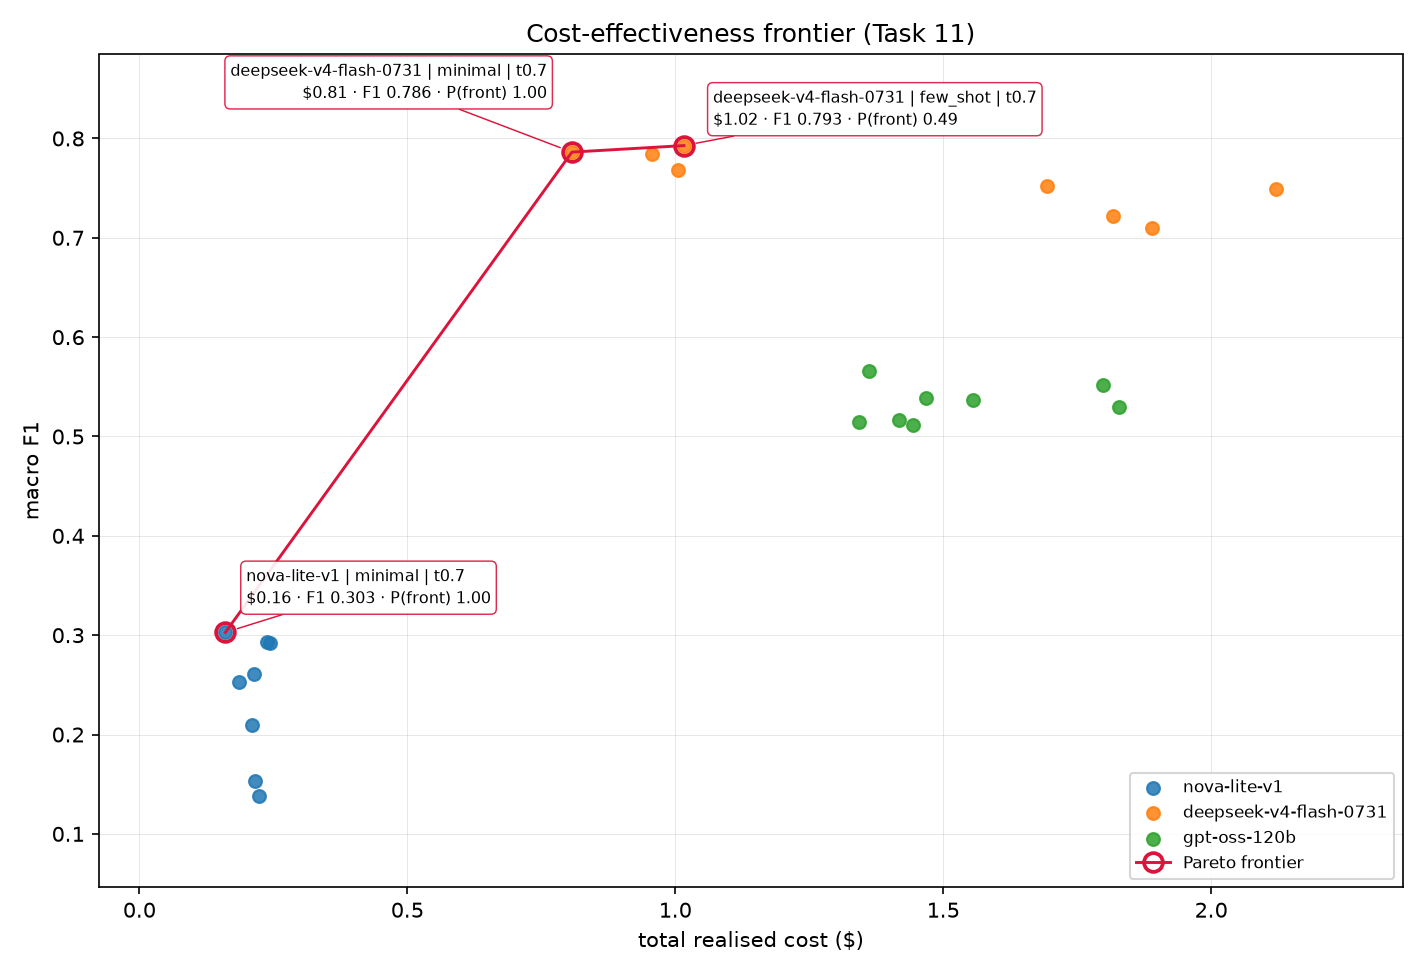

In [ ]:
display(Image(filename=str(FIGURES / "frontier.png")))


## Failure sensitivity

In [ ]:
print(report.failure_summary(data))


1920 runs total: 98 failed, 216 abstained (abstention is model behaviour, not a failure, and is not counted among the 98).
  76 context overflows, 22 timeouts (76 + 22 = 98).
  openrouter/amazon/nova-lite-v1: 76 failed run(s)
  openrouter/deepseek/deepseek-v4-flash-0731: 22 failed run(s)
context_overflow is genuinely ambiguous — inefficient search burning the context window (model behaviour) versus a site too large for a 128k window regardless of search quality (infrastructure); a sample of one model per failure type cannot separate the two readings, and this report does not resolve it.


In [ ]:
comparisons = sens.compare_with_and_without_failures(data)
print(report.sensitivity_table(comparisons))


SENSITIVITY (D-D) — macro F1 with vs without failed (timed-out / context-overflow) runs
  config                                                                  primary survivors    delta  n excl.
  openrouter/amazon/nova-lite-v1 | chain_of_thought | t0.0                  0.138     0.203    0.065       20
  openrouter/amazon/nova-lite-v1 | chain_of_thought | t0.7                  0.153     0.171    0.018       11
  openrouter/amazon/nova-lite-v1 | few_shot | t0.0                          0.293     0.347    0.055       16
  openrouter/amazon/nova-lite-v1 | few_shot | t0.7                          0.253     0.300    0.047        8
  openrouter/amazon/nova-lite-v1 | minimal | t0.0                           0.292     0.320    0.028        9
  openrouter/amazon/nova-lite-v1 | minimal | t0.7                           0.303     0.338    0.036        8
  openrouter/amazon/nova-lite-v1 | structured | t0.0                        0.209     0.209    0.000        2
  openrouter/amazon/nova-lite-v1

## Runtime health

In [ ]:
print(report.runtime_health_table(tel.runtime_health()))

RUNTIME HEALTH — conformance, retries and token totals
  runs                       1920
  schema-invalid output      161 (8.4% of runs)
      nova-lite-v1              138
      deepseek-v4-flash-0731    22
      gpt-oss-120b              1
  runs retried               91 (max attempts 5)
  step budget exhausted      26
  submit failed              37
  input tokens               177,448,210
  output tokens              20,572,889
  unattributable false pos.  854

Token totals are what make cost transferable: dollars are a function of this grid's prices on the day, tokens are not. 'unattributable false positives' are extractions matching no ground-truth row at all; score.py already fixes how precision treats them, and that decision is not restated here — the count is surfaced so the size of the affected population is visible.


## Cost per recovered opportunity

In [ ]:
cost_rows = tel.cost_per_true_positive(data)
print(report.cost_per_tp_table(cost_rows))

COST PER TRUE POSITIVE — realised spend per recovered opportunity; the unit cost that survives a change of denominator
  config                                                                    cost $    n TP    $ / TP  cost excl.
  openrouter/amazon/nova-lite-v1 | minimal | t0.7                           0.1604     102    0.0016           8
  openrouter/amazon/nova-lite-v1 | few_shot | t0.7                          0.1864      93    0.0020           8
  openrouter/deepseek/deepseek-v4-flash-0731 | minimal | t0.7               0.8071     384    0.0021           0
  openrouter/amazon/nova-lite-v1 | minimal | t0.0                           0.2439     115    0.0021           9
  openrouter/amazon/nova-lite-v1 | few_shot | t0.0                          0.2381     111    0.0021          16
  openrouter/amazon/nova-lite-v1 | structured | t0.7                        0.2144      92    0.0023           2
  openrouter/deepseek/deepseek-v4-flash-0731 | structured | t0.7            0.9562     372

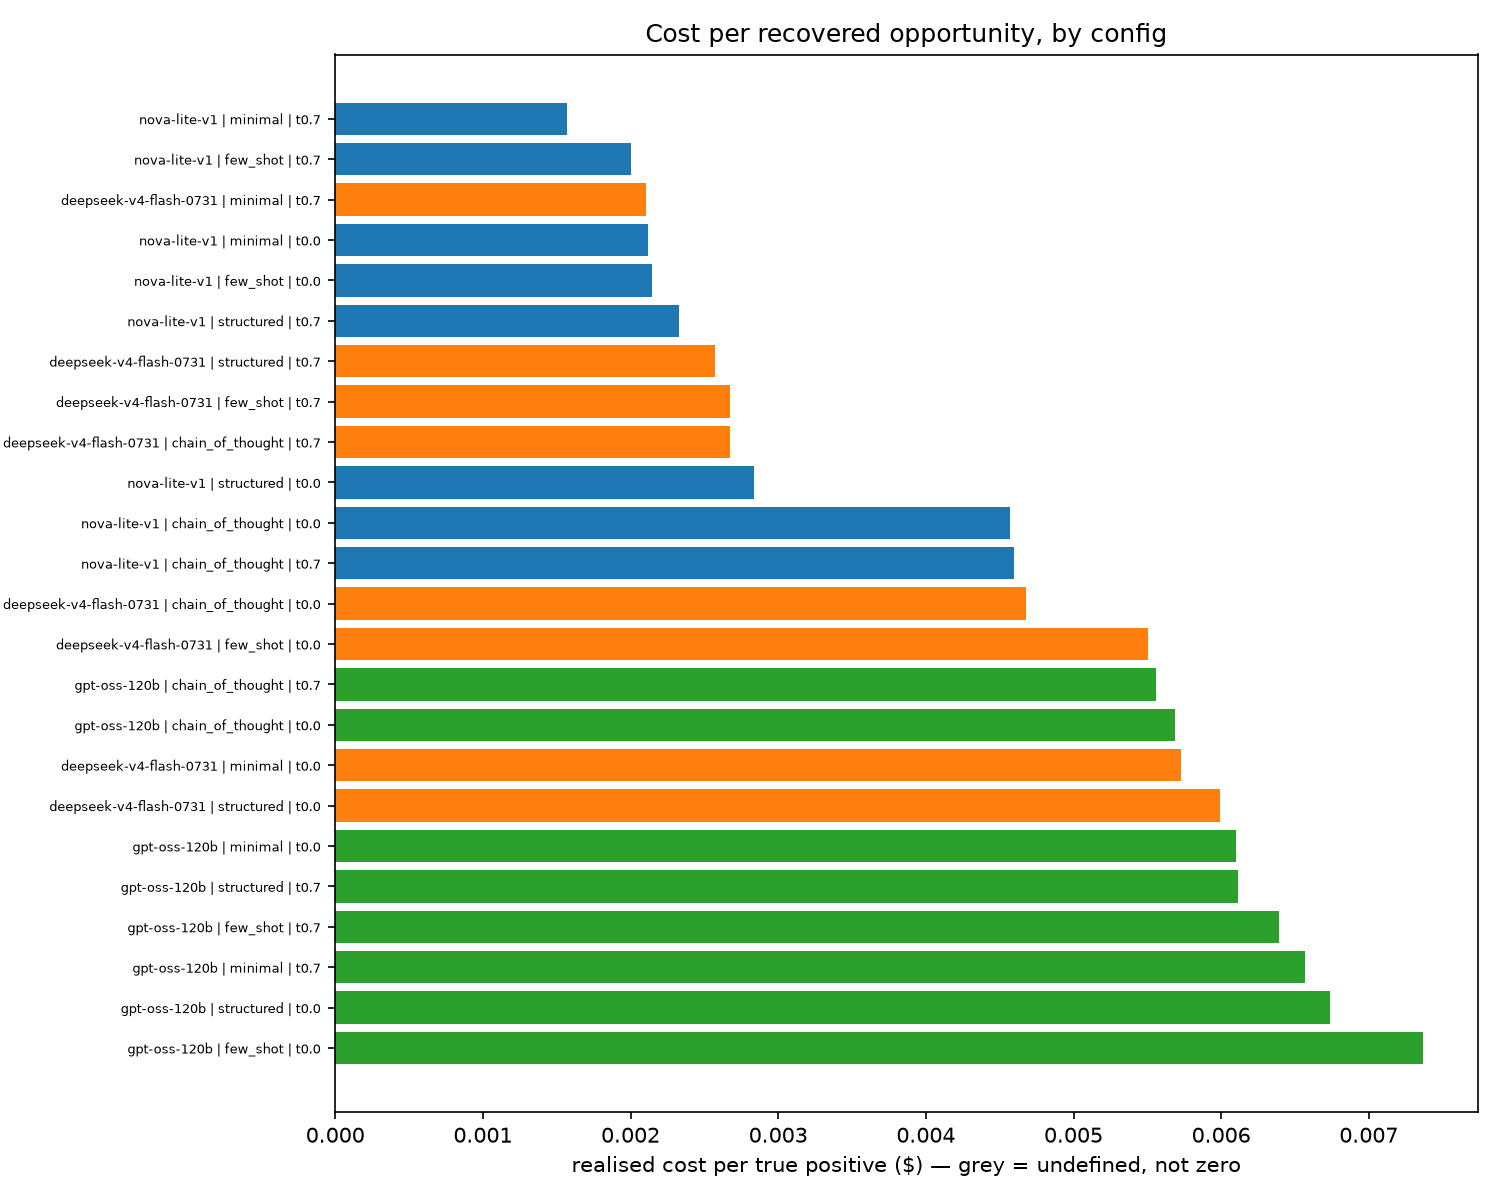

In [ ]:
display(Image(filename=str(FIGURES / "cost_per_tp.png")))

## Latency

In [ ]:
latency = tel.latency_profiles(data)
print(report.latency_table(latency))

LATENCY (seconds) — realised wall-clock per run
  group                      n runs  n defined      mean       p50        p95        max
  nova-lite-v1                  640        564      19.2       9.4       34.8      739.0
  gpt-oss-120b                  640        640      84.9      56.7      179.7     3455.8
  deepseek-v4-flash-0731        640        640     656.2     196.0     3715.7     5400.0

A run that died of context overflow has no defined latency (there is no completion time for a run that never completed) and is excluded from every statistic here; a timed-out run's latency IS defined but is the cap, not a measurement of the work, so it should be read as censored. A mean far above the p50 means the group is usually fast and occasionally catastrophic — the shape a mean alone would hide. Percentiles use numpy's default linear interpolation.


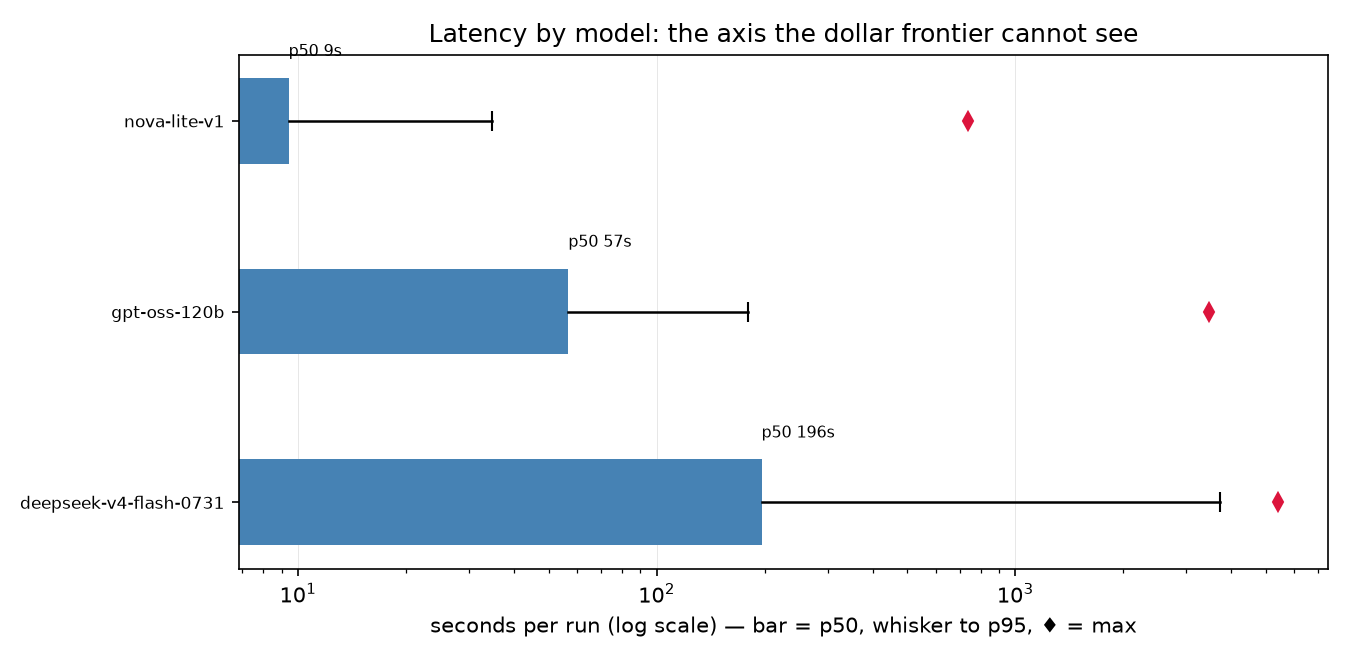

In [ ]:
display(Image(filename=str(FIGURES / "latency.png")))

## Abstention

In [ ]:
abstention = tel.abstention_profiles(data)
print(report.abstention_table(abstention))

ABSTENTION — runs that correctly reported nothing; never counted as failures (D-D), but recall is 0 for that funder either way
  group                      n runs  n abstained     rate
  nova-lite-v1                  640          149    0.233
  gpt-oss-120b                  640           62    0.097
  deepseek-v4-flash-0731        640            5    0.008

'Found nothing' and 'found the wrong thing' are different product failures with different fixes; F1 alone pools them. A group with a high abstention rate has part of its F1 deficit explained by refusal rather than by error.


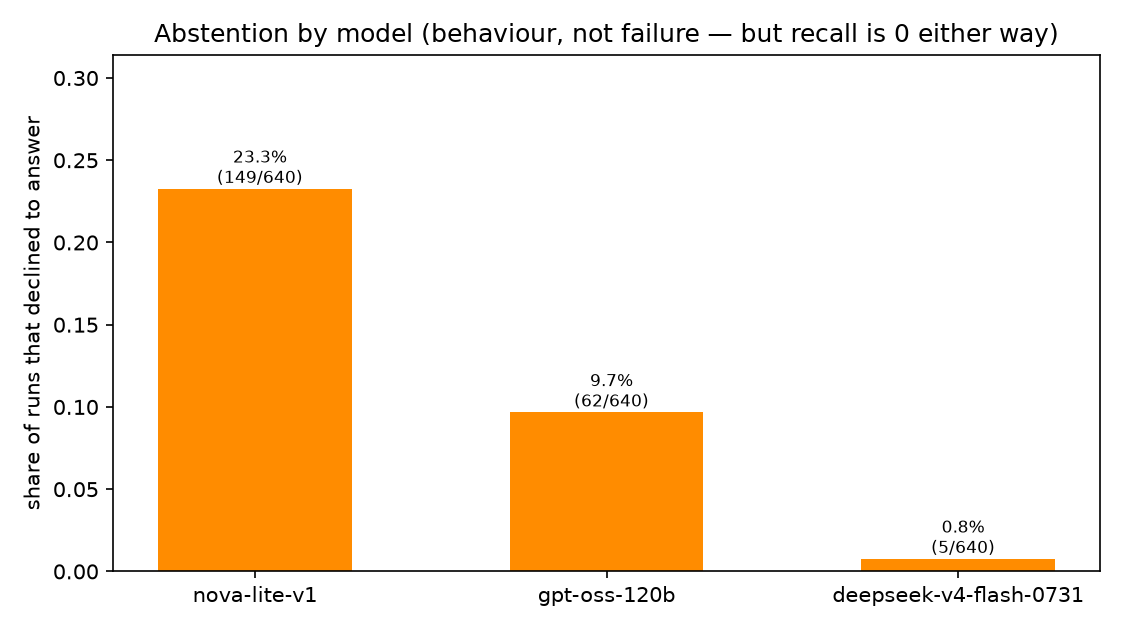

In [ ]:
display(Image(filename=str(FIGURES / "abstention.png")))

## False-positive composition

In [ ]:
fp_profiles = err.fp_reason_totals(data)
print(report.fp_reason_table(fp_profiles))

FALSE-POSITIVE COMPOSITION — counts, and each reason's share of that group's own false positives
  group                      n FP     ambiguous_title          distractor     unlabelled_page           duplicate      fabricated_url
  gpt-oss-120b                440           173 (39%)           145 (33%)            74 (17%)             39 (9%)              9 (2%)
  nova-lite-v1                420           110 (26%)           106 (25%)           182 (43%)              6 (1%)             16 (4%)
  deepseek-v4-flash-0731      419           206 (49%)           127 (30%)            84 (20%)              2 (0%)                   —

`ambiguous_title` is charged when a candidate's URL is shared by more than one ground-truth row and its title does not match — which is exactly the 'packed' funders of D-E (funders.py). Its size here is therefore the measure of how much of the structural-complexity result is scoring strictness rather than page difficulty; this table reports the composition and doe

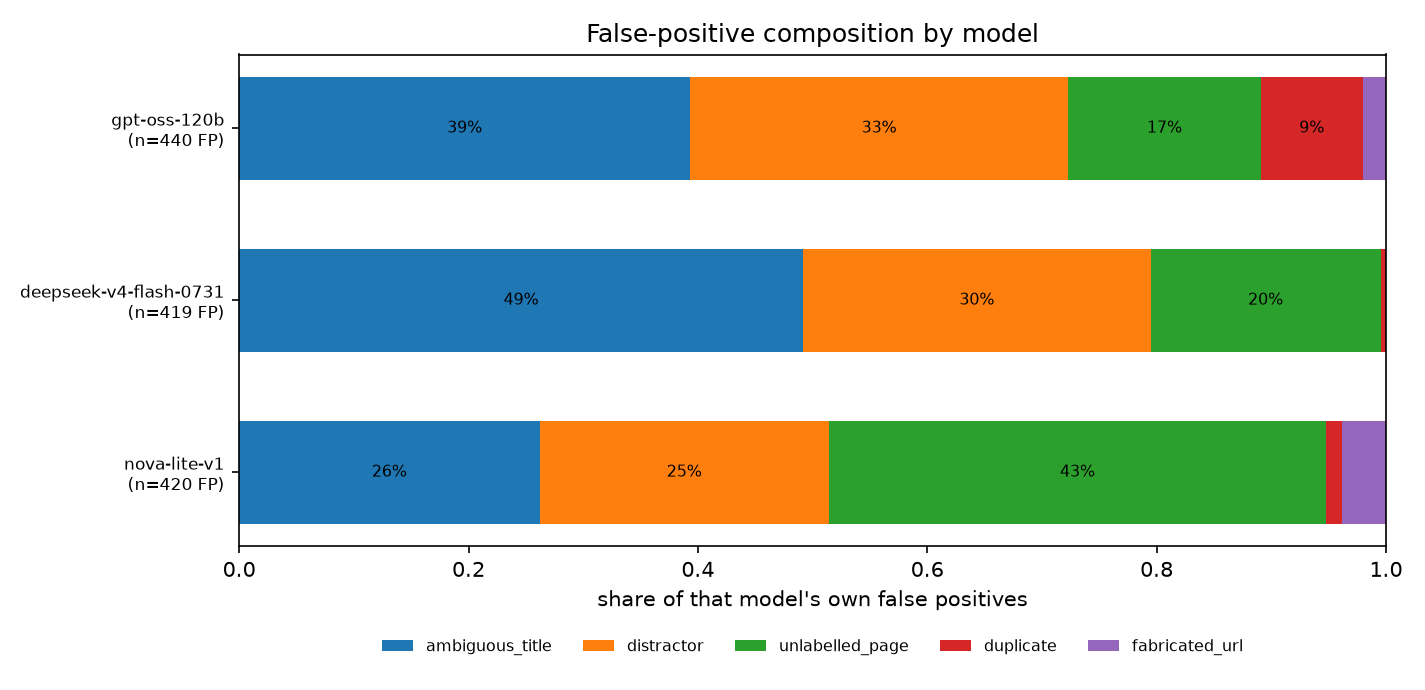

In [ ]:
display(Image(filename=str(FIGURES / "fp_reasons.png")))

## Fabrication

In [ ]:
fabrication = err.fabrication_totals(data)
print(report.fabrication_table(fabrication))

FABRICATION — invented items; a fabricated funding URL is the worst output class for this product, worse than a miss
  group                      n runs  n fabricated  runs fabricating  mean halluc.  n rate def.
  nova-lite-v1                  640            16                 6        0.0104          353
  gpt-oss-120b                  640             9                 5        0.0057          577
  deepseek-v4-flash-0731        640             0                 0        0.0000          613

'mean halluc.' averages only over runs with a DEFINED hallucination rate: a run that extracted nothing has no rate, and coercing that to 0 would read as scrupulous rather than silent. '—' means no run in the group had a defined rate.


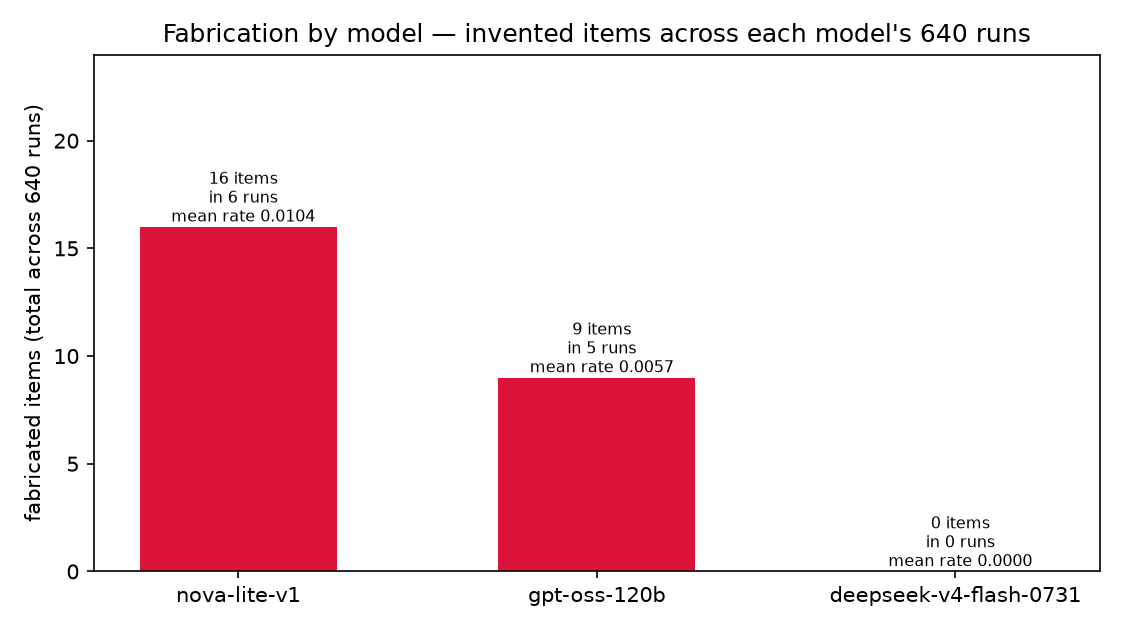

In [ ]:
display(Image(filename=str(FIGURES / "fabrication.png")))

## All tables as text

In [ ]:
print((FIGURES / "report.txt").read_text())

################################################################################
LEADERBOARD
################################################################################
LEADERBOARD — macro F1 across all 24 configurations, best first
    #  config                                                                  macroF1   macroP   macroR  funders
    1  openrouter/deepseek/deepseek-v4-flash-0731 | few_shot | t0.7              0.793    0.847    0.777       16
    2  openrouter/deepseek/deepseek-v4-flash-0731 | minimal | t0.7               0.786    0.835    0.782       16
    3  openrouter/deepseek/deepseek-v4-flash-0731 | structured | t0.7            0.784    0.853    0.764       16
    4  openrouter/deepseek/deepseek-v4-flash-0731 | chain_of_thought | t0.7      0.768    0.822    0.762       16
    5  openrouter/deepseek/deepseek-v4-flash-0731 | chain_of_thought | t0.0      0.752    0.847    0.748       16
    6  openrouter/deepseek/deepseek-v4-flash-0731 | structured | t0.0         